In [ ]:
from pathlib import Path

import yaml
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
df = pd.concat([pd.read_table(file, sep="\t") for file in snakemake.input.resfinder], ignore_index=True)
metadata = pd.read_csv(snakemake.input.contig_metadata)
metadata["Contig ID"] = metadata["contig_name"].str.extract(r"_(\d+)").fillna(0).astype(int) + 1
metadata["topology"] = metadata["topology"].fillna("circular")

In [ ]:
df = df.merge(metadata, how="left", left_on="SEQUENCE", right_on="contig_name")

In [ ]:
df["Genomic context"] = df["SEQUENCE"].apply(lambda x: "Plasmid" if x.startswith("p") else "Chromosome")
df["Genomic context"] = df.apply(lambda x: "Linear Contig" if not x["topology"] == "circular" else x["Genomic context"], axis=1)

In [ ]:
x = df["contig_size"].to_numpy()
df["Contig size"] = np.select(
    [x < 20000, x < 500000],
    ["Small (<20kb)", "Medium (20-500kb)"],
    default="Large (>500kb)"
)

In [ ]:
df["Contig size"].value_counts(dropna=False)

Contig Size
Large (>500kb)       90
Medium (20-500kb)    45
Small (<20kb)         8
Name: count, dtype: int64

/tmp/ipykernel_3394010/3632070360.py:8: UserWarning: The palette list has more values (8) than needed (5), which may not be intended.
  g = sns.relplot(subset,


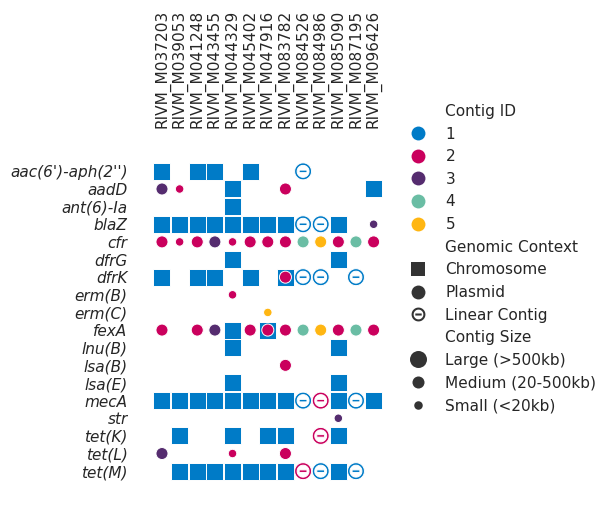

In [ ]:
rivm_palette = ['#007bc7','#ca005d','#552c6f','#6abda4', '#ffb612', '#e17000', '#777b00', '#94710a']
subset = df[df["sample_name"].str.contains("RIVM_M")].copy()
subset["PRODUCT"] = pd.Categorical(subset["PRODUCT"], ordered=True)
subset["sample_name"] = pd.Categorical(subset["sample_name"], ordered=True)
subset = subset.sort_values(["sample_name", "Contig ID"], ascending=True)
markers = {"Plasmid" : "o", "Chromosome" : "s", "Linear Contig" : r"$\mathbf{\circleddash}$"}
sns.set_style(style="white")
g = sns.relplot(subset,
    y="PRODUCT",
    x="sample_name", 
    style="Genomic context",
    markers=markers,
    hue="Contig ID",
    size = "Contig size",
    sizes = [150, 75, 37.5],
    s=100,
    palette=rivm_palette
)
g.set(xlabel="", ylabel="", aspect="equal")
g.despine(left=True, bottom=True)
g.ax.margins(0.1)
g.ax.tick_params(labeltop=True, labelbottom=False)
for label in g.ax.get_xticklabels():
    label.set_rotation(90)
for label in g.ax.get_yticklabels():
    label.set_fontstyle("italic")
plt.savefig(snakemake.output.fig_2a, bbox_inches="tight")

/tmp/ipykernel_3394010/4199928787.py:8: UserWarning: The palette list has more values (8) than needed (2), which may not be intended.
  g = sns.relplot(subset,


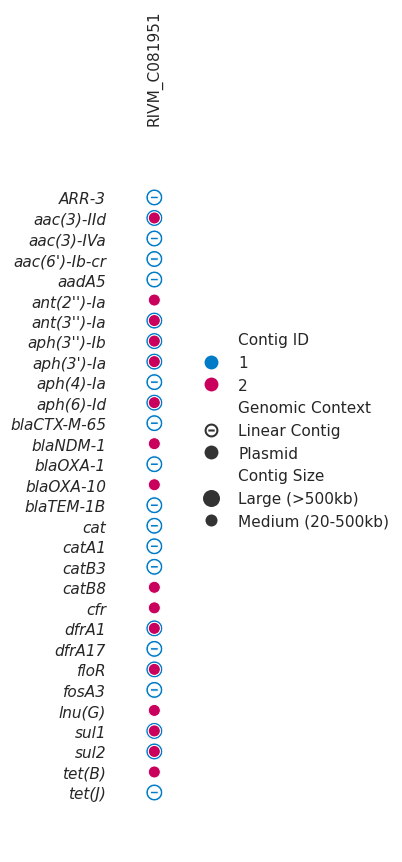

In [ ]:
rivm_palette = ['#007bc7','#ca005d','#552c6f','#6abda4', '#ffb612', '#e17000', '#777b00', '#94710a']
subset = df[df["sample_name"].str.contains("RIVM_C")].copy()
subset["PRODUCT"] = pd.Categorical(subset["PRODUCT"], ordered=True)
subset["sample_name"] = pd.Categorical(subset["sample_name"], ordered=True)
subset = subset.sort_values(["sample_name", "Contig ID"], ascending=True)
markers = {"Plasmid" : "o", "Chromosome" : "s", "Linear Contig" : r"$\mathbf{\circleddash}$"}
sns.set_theme(style="white")
g = sns.relplot(subset,
    y="PRODUCT",
    x="sample_name", 
    style="Genomic context",
    markers=markers,
    hue="Contig ID",
    size = "Contig size",
    sizes = [150, 75],
    s=100,
    height=8,
    aspect=0.4,
    palette=rivm_palette
)
g.set(xlabel="", ylabel="")
g.despine(left=True, bottom=True)
g.ax.margins(0.1)
g.ax.tick_params(labeltop=True, labelbottom=False)
for label in g.ax.get_xticklabels():
    label.set_rotation(90)
for label in g.ax.get_yticklabels():
    label.set_fontstyle("italic")
plt.savefig(snakemake.output.fig_2b, bbox_inches="tight")

In [ ]:
isolate_metadata = pd.read_csv(snakemake.input.isolate_metadata)
plasmid_metadata = df[df["PRODUCT"] == "cfr"][["contig_name", "sample_name", "contig_size", "gc_content", "topology"]]
plasmid_metadata.columns = ["accession", "sample_name", "contig_size", "gc_content", "topology"]
plasmid_metadata = plasmid_metadata.merge(isolate_metadata, on="sample_name")
plasmid_metadata.to_csv(snakemake.output.fig_2c, index=False)